In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Toxic Comment Classification using NLP and N-gram Vectorization

## BUSINESS OVERVIEW

Moderating user-generated content is essential for maintaining healthy online communities. Toxic language such as insults, threats, hate speech, and abusive content can damage user experience and platform safety.

The objective of this project is to build a Natural Language Processing model that can automatically identify toxic content from comment text. This can help improve moderation workflows and reduce the workload of human moderators.



## DATASET INFORMATION

The main goal of this project is to predict which toxicity categories apply to a given comment based on its text.

The model generates predictions for the following labels:

- toxic
- severe_toxic
- obscene
- threat
- insult
- identity_hate

Therefore, this is not a single-target classification problem, but a multi-label classification problem.

## PROJECT TARGET

There is no single target variable in this project. The model predicts 6 different toxicity labels at the same time.

The target labels are:

- toxic
- severe_toxic
- obscene
- threat
- insult
- identity_hate

This makes the task a multi-label classification problem.

## LOADING LIBRARIES

In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import re
import string

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

## LOAD DATASET

In [2]:
train = pd.read_csv("/Users/kiahvaidya/Desktop/smtd3/dataset/train.csv")
test = pd.read_csv("/Users/kiahvaidya/Desktop/smtd3/dataset/test.csv")
sample_sub = pd.read_csv("/Users/kiahvaidya/Desktop/smtd3/dataset/sample_submission.csv")
test_labels = pd.read_csv("/Users/kiahvaidya/Desktop/smtd3/dataset/test_labels.csv")

train.shape, test.shape

((159571, 8), (153164, 2))

## EDA

In [3]:
train.head()    

,id,comment_text,toxic,severe_toxic,obscene,threat,insult,identity_hate
0,0000997932d777bf,Explanation\nWhy the edits made under my usern...,0,0,0,0,0,0
1,000103f0d9cfb60f,D'aww! He matches this background colour I'm s...,0,0,0,0,0,0
2,000113f07ec002fd,"Hey man, I'm really not trying to edit war. It...",0,0,0,0,0,0
3,0001b41b1c6bb37e,"""\nMore\nI can't make any real suggestions on ...",0,0,0,0,0,0
4,0001d958c54c6e35,"You, sir, are my hero. Any chance you remember...",0,0,0,0,0,0


In [4]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 159571 entries, 0 to 159570
Data columns (total 8 columns):
 #   Column         Non-Null Count   Dtype 
---  ------         --------------   ----- 
 0   id             159571 non-null  object
 1   comment_text   159571 non-null  object
 2   toxic          159571 non-null  int64 
 3   severe_toxic   159571 non-null  int64 
 4   obscene        159571 non-null  int64 
 5   threat         159571 non-null  int64 
 6   insult         159571 non-null  int64 
 7   identity_hate  159571 non-null  int64 
dtypes: int64(6), object(2)
memory usage: 9.7+ MB


#### LABEL DISTRIBUTION

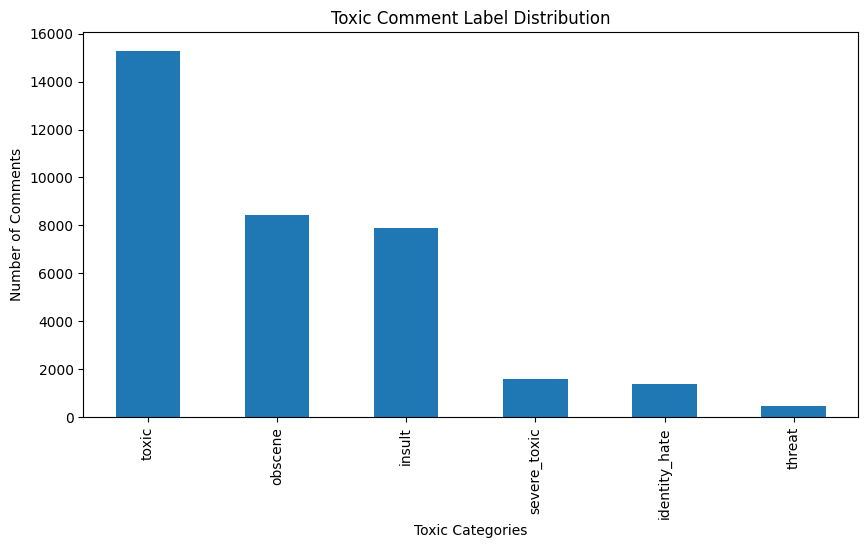

In [5]:
labels = train.columns[2:]

train[labels].sum().sort_values(ascending=False).plot(kind="bar", figsize=(10,5))

plt.title("Toxic Comment Label Distribution")
plt.ylabel("Number of Comments")
plt.xlabel("Toxic Categories")

plt.show()

#### COMMENT LENGTH ANALYSIS

We analyze the length of comments to understand the distribution of text sizes in the dataset.

In [6]:
train["comment_length"] = train["comment_text"].str.len()

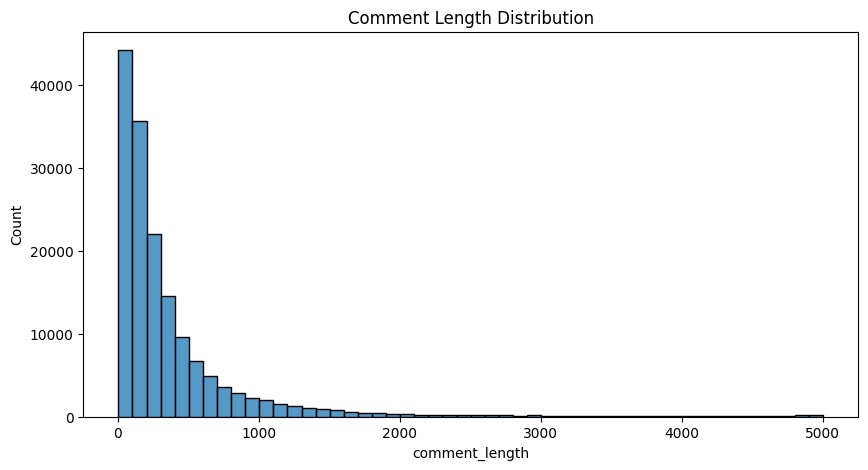

In [7]:
plt.figure(figsize=(10,5))

sns.histplot(train["comment_length"], bins=50)

plt.title("Comment Length Distribution")

plt.show()

The distribution of comment lengths shows that most comments are relatively short.
The majority of comments fall between 0 and 500 characters, while a smaller number of comments are significantly longer.

The distribution is right-skewed, meaning there are a few very long comments extending beyond 2000 characters.

This observation is important for Natural Language Processing because:

Most comments contain limited text information.

Extremely long comments are rare.


#### Toxic vs Non-Toxic Comment Length

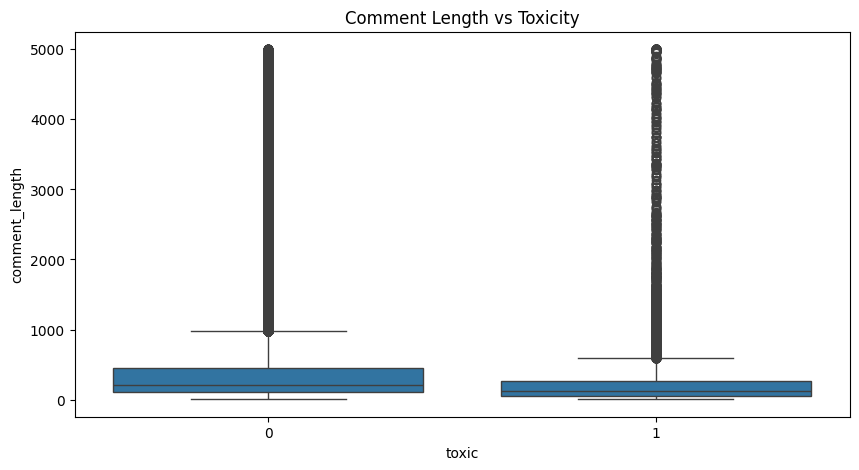

In [8]:
plt.figure(figsize=(10,5))

sns.boxplot(x=train["toxic"], y=train["comment_length"])

plt.title("Comment Length vs Toxicity")

plt.show()

The boxplot compares the length of toxic and non-toxic comments.

From the visualization we observe:

The median length of toxic comments is slightly shorter than non-toxic comments.

Both categories contain extreme outliers, with some comments exceeding 4000–5000 characters.

The majority of comments for both classes are concentrated below 500 characters.

This indicates that comment length alone is not a strong indicator of toxicity.
Instead, the content and wording of the comment play a more important role.


#### Toxic Label Correlation Heatmap

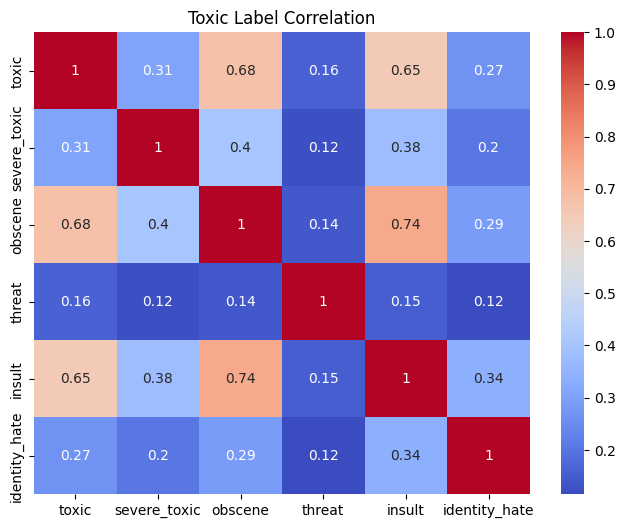

In [9]:
plt.figure(figsize=(8,6))

sns.heatmap(train.iloc[:,2:8].corr(), annot=True, cmap="coolwarm")

plt.title("Toxic Label Correlation")

plt.show()

## NLP Feature Engineering

1️⃣ lowercase
2️⃣ punctuation removal
3️⃣ number removal
4️⃣ stopwords removal
5️⃣ lemmatization
6️⃣ vectorization

In [10]:
train["comment_text"] = train["comment_text"].str.lower()         # 1️⃣ lowercase   
train["comment_text"]=train["comment_text"].str.replace(r"[^\w\s]", "", regex=True) # 2️⃣ punctuation removal 
train["comment_text"]=train["comment_text"].str.replace(r"\d+", "", regex=True) #3️⃣ Number Removal
train["comment_text"]=train["comment_text"].str.replace("\n", " ") #Remove Newline Characters
train["comment_text"]=train["comment_text"].str.replace("\r"," " ,regex=True) #Remove line braks

In [24]:
from sklearn.feature_extraction.text import TfidfVectorizer

vectorizer = TfidfVectorizer(stop_words="english")
X = vectorizer.fit_transform(train["comment_text"])

In [25]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer

In [26]:
train["comment_text"] = train["comment_text"].apply(lambda x: " ".join(x) if isinstance(x, list) else x) # 6️⃣ vectorization

## Modelling

In [27]:
x = train['comment_text']
y = train[['toxic', 'severe_toxic', 'obscene', 'threat', 'insult', 'identity_hate']]

In [28]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

In [29]:
vect = CountVectorizer(ngram_range=(1,2))

In [30]:
x_train_vec=vect.fit_transform(x_train)
x_test_vec=vect.transform(x_test)

In [31]:
from sklearn.feature_extraction.text import TfidfVectorizer
vect = TfidfVectorizer(ngram_range=(1,2))
x_sayisal = vect.fit_transform(train['comment_text']) 
y = train[['toxic', 'severe_toxic', 'obscene', 'threat', 'insult', 'identity_hate']]

In [32]:
from sklearn.multiclass import OneVsRestClassifier
from sklearn.linear_model import LogisticRegression

In [33]:
model = OneVsRestClassifier(LogisticRegression(max_iter=1000))

In [34]:
from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(
    x_sayisal, y, test_size=0.2, random_state=42
)

In [35]:
model.fit(x_train, y_train)

,"estimator estimator: estimator objectA regressor or a classifier that implements :term:`fit`.When a classifier is passed, :term:`decision_function` will be usedin priority and it will fallback to :term:`predict_proba` if it is notavailable.When a regressor is passed, :term:`predict` is used.",LogisticRegre...max_iter=1000)
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation: the `n_classes`one-vs-rest problems are computed in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: 0.20 `n_jobs` default changed from 1 to None",None
,"verbose verbose: int, default=0The verbosity level, if non zero, progress messages are printed.Below 50, the output is sent to stderr. Otherwise, the output is sentto stdout. The frequency of the messages increases with the verbositylevel, reporting all iterations at 10. See :class:`joblib.Parallel` formore details... versionadded:: 1.1",0
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=

In [36]:
pred = model.predict(x_test)

In [37]:
from sklearn.metrics import f1_score

f1_score(y_test, pred, average="micro")

0.5778251599147122

In [38]:
from sklearn.metrics import f1_score, precision_score, recall_score

label_scores = pd.DataFrame({
    "Label": y.columns,
    "Precision": precision_score(y_test, pred, average=None, zero_division=0),
    "Recall": recall_score(y_test, pred, average=None, zero_division=0),
    "F1 Score": f1_score(y_test, pred, average=None, zero_division=0)
})

label_scores.sort_values("F1 Score", ascending=False)

,Label,Precision,Recall,F1 Score
0,toxic,0.947436,0.483639,0.640381
2,obscene,0.950058,0.476968,0.635093
4,insult,0.870112,0.385998,0.534764
1,severe_toxic,0.530864,0.133956,0.213930
5,identity_hate,0.739130,0.057823,0.107256
3,threat,0.666667,0.027027,0.051948


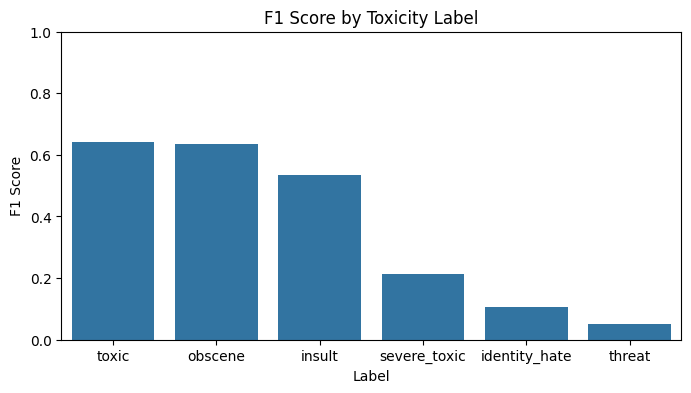

In [39]:
plt.figure(figsize=(8,4))

sns.barplot(data=label_scores.sort_values("F1 Score", ascending=False), x="Label", y="F1 Score")

plt.title("F1 Score by Toxicity Label")
plt.xlabel("Label")
plt.ylabel("F1 Score")
plt.ylim(0, 1)

plt.show()

# CONCLUSION

In this project, a Natural Language Processing pipeline was developed to classify toxic comments from Wikipedia discussions. Text data was transformed into numerical representations using n-gram based vectorization, allowing the model to capture both individual words and short word combinations.

The evaluation results reveal that the model performs relatively well on more frequent toxicity categories such as toxic and obscene, achieving F1 scores around 0.63. The model also shows moderate performance for the insult category with an F1 score of approximately 0.50. These results indicate that the model can successfully learn common toxic language patterns that frequently appear in the dataset.

However, the model struggles with less frequent labels such as severe_toxic, identity_hate, and threat. In particular, the threat category shows a very low F1 score (around 0.08), while identity_hate remains difficult to detect due to its extremely low recall. This is primarily caused by class imbalance, as these categories appear much less frequently in the dataset.

The precision scores across most labels are relatively high, suggesting that when the model predicts a toxic category, it is often correct. However, the recall values for rare classes remain low, meaning the model fails to detect many true toxic cases in those categories.

Overall, the model demonstrates that n-gram based text vectorization combined with classical machine learning models can effectively detect common toxic patterns in online comments. Nevertheless, performance could be further improved by addressing class imbalance and by adopting more advanced Natural Language Processing approaches such as TF-IDF weighting, class balancing techniques, or transformer-based language models.

In [40]:
# Submission

test_vec = vect.transform(test["comment_text"])

pred_test = model.predict(test_vec)

submission = pd.DataFrame(pred_test, columns=y.columns)

submission.insert(0,"id",test["id"])

submission.to_csv("submission.csv", index=False)

In [41]:
import joblib
from sklearn.multiclass import OneVsRestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.feature_extraction.text import TfidfVectorizer

x= train["comment_text"]
y = train[["toxic", "severe_toxic", "obscene", "threat", "insult", "identity_hate"]]

vectorizer = TfidfVectorizer(ngram_range=(1, 2), max_features=20000)
x_vec = vectorizer.fit_transform(x)

model = OneVsRestClassifier(LogisticRegression(max_iter=1000))
model.fit(x_vec, y)

joblib.dump(model, "toxic_model.pkl")
joblib.dump(vectorizer, "toxic_vectorizer.pkl")
joblib.dump(y.columns.tolist(), "toxic_columns.pkl")

['toxic_columns.pkl']